### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Tree-Based Classifiers**

| Technique | Idea | Reduces | Key hyperparameters |
|---|---|---|---|
| **Decision tree (CART)** | recursive splits that maximise the **impurity decrease** | – (high variance) | depth, `min_samples_leaf`, `ccp_alpha` |
| **Random Forest** | many de-correlated trees (bootstrap + random attributes), **vote** | **variance** | trees, `max_features` |
| **AdaBoost** | sequence of weak trees, **re-weighting** the hard cases | **bias** | trees, learning rate |
| **Gradient Boosting** | each tree fits the **gradient** of the loss | bias | trees, learning rate, depth, subsample |
| **XGBoost** | gradient boosting with **2nd-order** information and **regularisation** (λ, γ) | bias + overfitting control | η, depth, λ, γ |

Every technique is evaluated on the same problem: **malignant × benign** (Breast Cancer, positive = malignant).

In [4]:
#Load the Breast Cancer Dataset and Split ( 70% Train / 30% Test, Stratified )
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

bc = load_breast_cancer(as_frame=True)
X, y = bc.data, (bc.target == 0).astype(int)                       # 1 = malignant
CLASSES = ["benign", "malignant"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape, "| malignant:", f"{y_train.mean():.1%}")
results = {}

train: (398, 30) | test: (171, 30) | malignant: 37.2%


### **2. Decision Tree (CART)**

At each node, choose the attribute and threshold that **maximise the impurity decrease**. For the **Gini impurity**:

$$G(S) = 1 - \sum_k p_k^2 \qquad \text{gain} = G(S) - \frac{n_L}{n}\,G(S_L) - \frac{n_R}{n}\,G(S_R)$$

A leaf predicts the **majority class** (and the class proportions as a probability).

root split from scratch : worst perimeter <= 112.8000 (Gini gain 0.3364)
root split scikit-learn : worst perimeter <= 112.8000


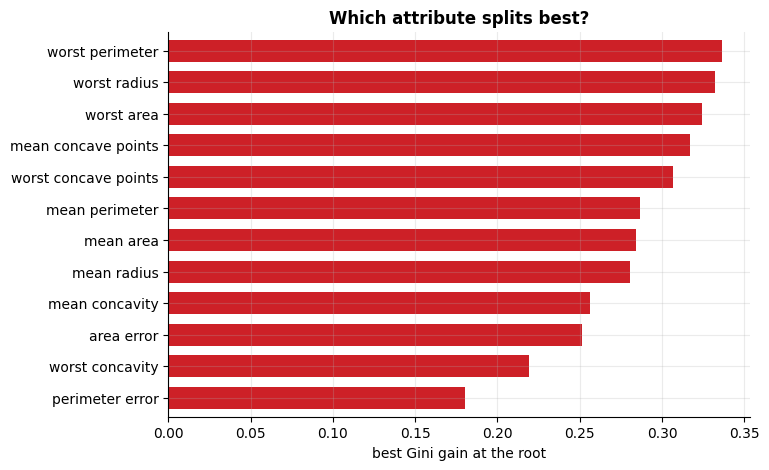

In [5]:
#CART Split Search from Scratch ( Gini Gain for Every Attribute and Threshold ) and Check Against scikit-learn
from sklearn.tree import DecisionTreeClassifier

def gini(y):
    p = np.bincount(y, minlength=2) / len(y)
    return 1 - (p ** 2).sum()

def best_split(Xa, ya):
    n, best = len(ya), {"gain": -1}
    g_parent = gini(ya)
    per_feature = {}
    for j in range(Xa.shape[1]):
        order = np.argsort(Xa[:, j])
        xs, ys = Xa[order, j], ya[order]
        left_pos = np.cumsum(ys)[:-1]; n_left = np.arange(1, n)
        right_pos = ys.sum() - left_pos; n_right = n - n_left
        g_left = 1 - (left_pos / n_left) ** 2 - ((n_left - left_pos) / n_left) ** 2
        g_right = 1 - (right_pos / n_right) ** 2 - ((n_right - right_pos) / n_right) ** 2
        gain = g_parent - (n_left * g_left + n_right * g_right) / n
        gain[xs[1:] == xs[:-1]] = -1                                                   # cannot split between equal values
        k = int(np.argmax(gain)); per_feature[X.columns[j]] = gain[k]
        if gain[k] > best["gain"]:
            best = {"gain": gain[k], "feature": X.columns[j], "threshold": (xs[k] + xs[k + 1]) / 2}
    return best, pd.Series(per_feature)

best, per_feature = best_split(X_train.to_numpy(), y_train.to_numpy())
stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"root split from scratch : {best['feature']} <= {best['threshold']:.4f} (Gini gain {best['gain']:.4f})")
print(f"root split scikit-learn : {X.columns[stump.tree_.feature[0]]} <= {stump.tree_.threshold[0]:.4f}")

plt.figure(figsize=(7.5, 5))
per_feature.sort_values().tail(12).plot.barh(color=RED, width=0.7); plt.xlabel("best Gini gain at the root"); plt.title("Which attribute splits best?")
plt.show()

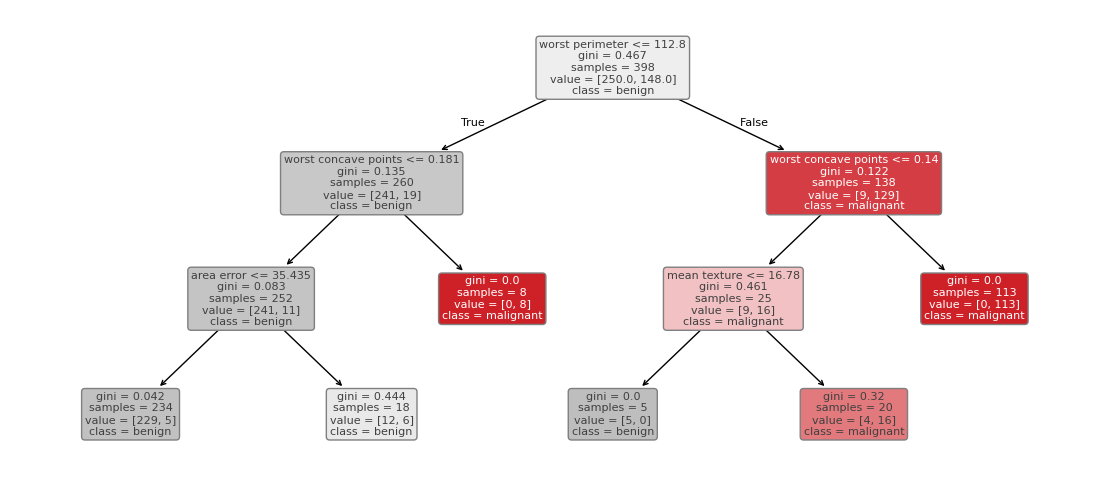

|--- worst perimeter <= 112.80
|   |--- worst concave points <= 0.18
|   |   |--- area error <= 35.44
|   |   |   |--- class: 0
|   |   |--- area error >  35.44
|   |   |   |--- class: 0
|   |--- worst concave points >  0.18
|   |   |--- class: 1
|--- worst perimeter >  112.80
|   |--- worst concave points <= 0.14
|   |   |--- mean texture <= 16.78
|   |   |   |--- class: 0
|   |   |--- mean texture >  16.78
|   |   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- class: 1



In [6]:
#Fit a Shallow Tree ( Depth 3 ): the Tree Diagram and the Rules in Text Form
from sklearn.tree import plot_tree, export_text
import re

tree3 = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(14, 6))
ann = plot_tree(tree3, feature_names=list(X.columns), class_names=CLASSES, filled=True, rounded=True, fontsize=8, ax=ax)
for a in ann:                                                                         # recolor with the course palette
    t = a.get_text(); mt = re.search(r"value = \[([^\]]*)\]", t)
    if not mt or a.get_bbox_patch() is None:
        continue
    v = np.array([float(x) for x in mt.group(1).split(",")]); frac = v[1] / v.sum()
    base = np.array([205, 32, 39]) / 255 if frac >= 0.5 else np.array([190, 190, 190]) / 255
    purity = abs(frac - 0.5) * 2
    a.get_bbox_patch().set_facecolor(base * purity + (1 - purity) * np.ones(3)); a.get_bbox_patch().set_edgecolor(GRAY)
    a.set_color("white" if (frac >= 0.5 and purity > 0.7) else DARK)
plt.show()
print(export_text(tree3, feature_names=list(X.columns), max_depth=3))

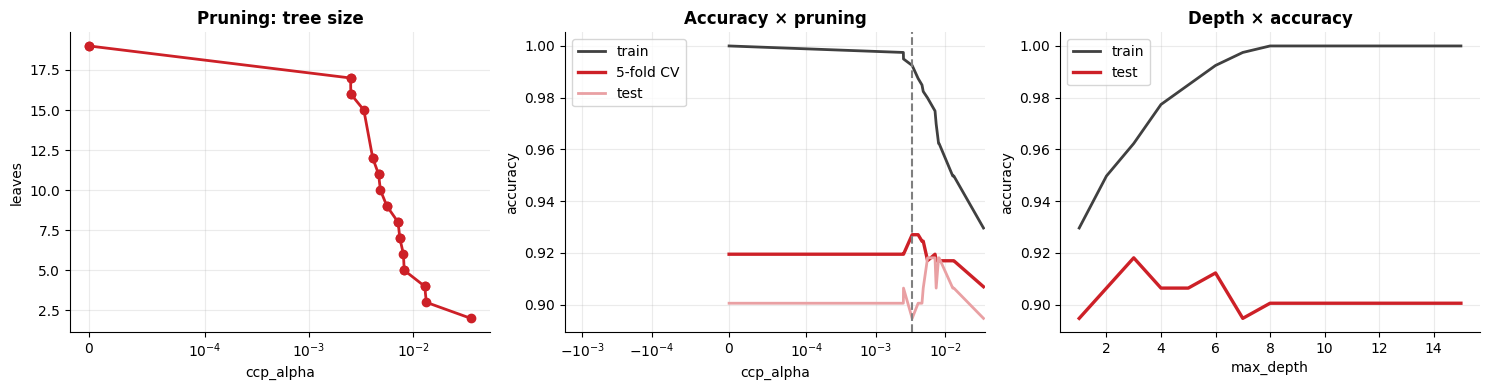

unpruned tree: depth 8, 19 leaves, test accuracy 0.901
pruned (α = 0.0034): depth 7, 15 leaves, test accuracy 0.895


In [7]:
#Decision Tree-Specific Metrics: Depth, Leaves, Pruning Path ( Cost-Complexity ) and Choice of α by Cross-Validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(path.ccp_alphas[:-1])
alphas = alphas[np.linspace(0, len(alphas) - 1, 25).astype(int)]

rows = []
for a in alphas:
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=RANDOM_STATE).fit(X_train, y_train)
    rows.append({"alpha": a, "leaves": t.get_n_leaves(), "depth": t.get_depth(), "train acc": t.score(X_train, y_train), "test acc": t.score(X_test, y_test),
                 "CV acc": cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=RANDOM_STATE), X_train, y_train, cv=cv5).mean()})
prune = pd.DataFrame(rows)
best_alpha = prune.loc[prune["CV acc"].idxmax(), "alpha"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(prune["alpha"], prune["leaves"], marker="o", color=RED, lw=2); axes[0].set_xscale("symlog", linthresh=1e-4); axes[0].set_xlabel("ccp_alpha"); axes[0].set_ylabel("leaves"); axes[0].set_title("Pruning: tree size")
axes[1].plot(prune["alpha"], prune["train acc"], color=DARK, lw=2, label="train"); axes[1].plot(prune["alpha"], prune["CV acc"], color=RED, lw=2.4, label="5-fold CV"); axes[1].plot(prune["alpha"], prune["test acc"], color=SOFT, lw=2, label="test")
axes[1].axvline(best_alpha, color=GRAY, ls="--"); axes[1].set_xscale("symlog", linthresh=1e-4); axes[1].set_xlabel("ccp_alpha"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy × pruning"); axes[1].legend()
depths = range(1, 16)
tr = [DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train) for d in depths]
axes[2].plot(depths, [t.score(X_train, y_train) for t in tr], color=DARK, lw=2, label="train"); axes[2].plot(depths, [t.score(X_test, y_test) for t in tr], color=RED, lw=2.4, label="test")
axes[2].set_xlabel("max_depth"); axes[2].set_ylabel("accuracy"); axes[2].set_title("Depth × accuracy"); axes[2].legend()
plt.tight_layout(); plt.show()
print(f"unpruned tree: depth {full_tree.get_depth()}, {full_tree.get_n_leaves()} leaves, test accuracy {full_tree.score(X_test, y_test):.3f}")
pruned = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"pruned (α = {best_alpha:.4f}): depth {pruned.get_depth()}, {pruned.get_n_leaves()} leaves, test accuracy {pruned.score(X_test, y_test):.3f}")

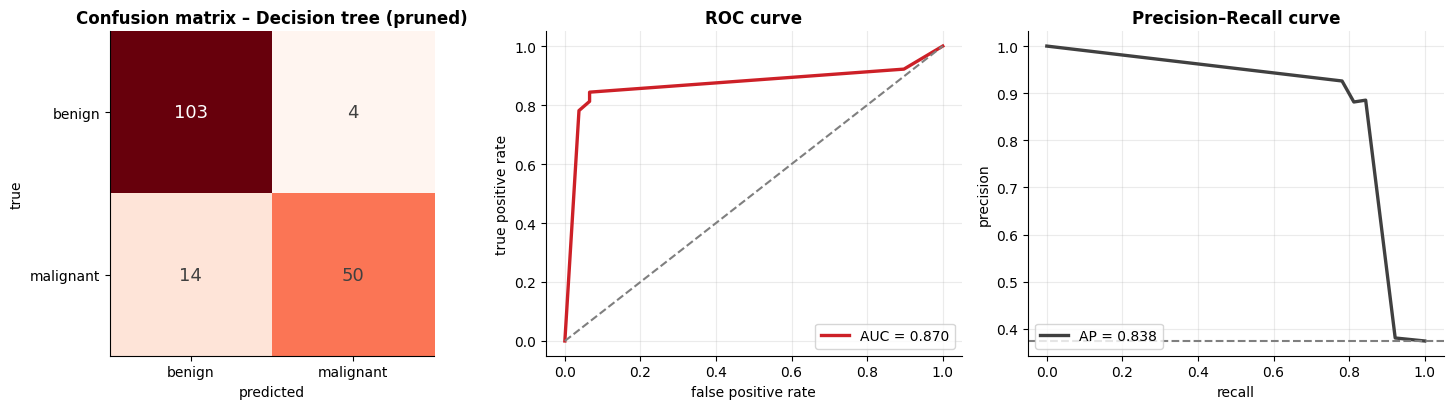

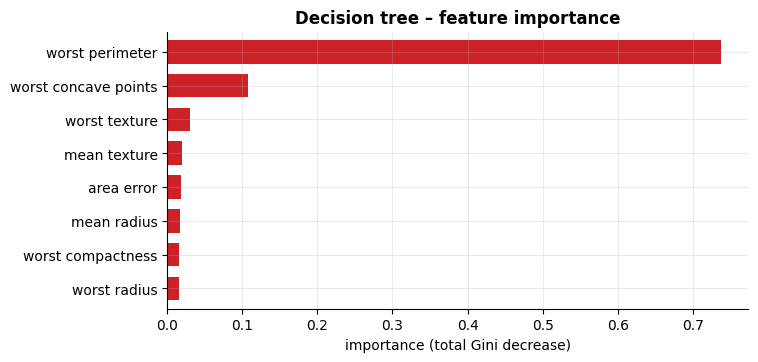

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Decision tree (pruned),0.895,0.872,0.926,0.781,0.847,0.774,0.87,0.838


In [8]:
#Evaluate the Pruned Tree ( Confusion Matrix, ROC and Precision-Recall ) and Show Its Feature Importances
import time
t0 = time.perf_counter(); pruned = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=RANDOM_STATE).fit(X_train, y_train); fit_time = time.perf_counter() - t0
p_tree = pruned.predict_proba(X_test)[:, 1]
results["Decision tree (pruned)"] = report_binary(y_test, pruned.predict(X_test), p_tree, "Decision tree (pruned)", CLASSES)
extra = {"Decision tree (pruned)": {"log loss": log_loss(y_test, np.clip(p_tree, 1e-3, 1 - 1e-3)), "fit time (s)": fit_time, "size": f"{pruned.get_n_leaves()} leaves"}}

imp = pd.Series(pruned.feature_importances_, index=X.columns).sort_values().tail(8)
plt.figure(figsize=(7.5, 3.6)); imp.plot.barh(color=RED, width=0.7); plt.xlabel("importance (total Gini decrease)"); plt.title("Decision tree – feature importance")
plt.show()
results["Decision tree (pruned)"].to_frame().T

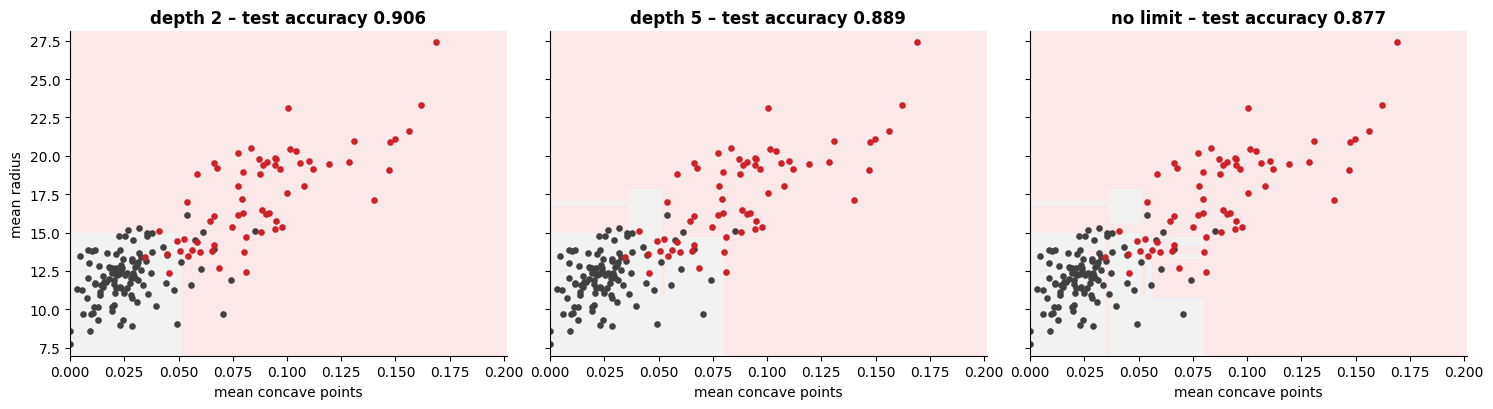

In [9]:
#Decision Regions on Two Attributes: Depth 2 ( Underfits ), Pruned and Unpruned ( Overfits )
from matplotlib.colors import ListedColormap
two = ["mean concave points", "mean radius"]
gx, gy = np.meshgrid(np.linspace(X[two[0]].min(), X[two[0]].max(), 250), np.linspace(X[two[1]].min(), X[two[1]].max(), 250))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)
for ax, depth, title in zip(axes, [2, 5, None], ["depth 2", "depth 5", "no limit"]):
    t = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE).fit(X_train[two], y_train)
    z = t.predict(pd.DataFrame(np.c_[gx.ravel(), gy.ravel()], columns=two)).reshape(gx.shape)
    ax.contourf(gx, gy, z, levels=[-0.5, 0.5, 1.5], colors=["#F2F2F2", "#FBE9EA"])
    ax.scatter(X_test[two[0]][y_test == 0], X_test[two[1]][y_test == 0], s=14, color=DARK); ax.scatter(X_test[two[0]][y_test == 1], X_test[two[1]][y_test == 1], s=14, color=RED)
    ax.set_title(f"{title} – test accuracy {t.score(X_test[two], y_test):.3f}"); ax.set_xlabel(two[0]); ax.grid(False)
axes[0].set_ylabel(two[1])
plt.tight_layout(); plt.show()

### **3. Random Forest**

* **Bagging:** each tree is trained on a **bootstrap sample** (≈ 63 % of the cases); the remaining **out-of-bag (OOB)** cases give a free validation
* **Random attributes:** each split considers only `max_features` attributes → trees **less correlated**
* Prediction = **vote / average** of the trees: the **variance falls**, the bias stays

OOB accuracy: 0.952 | test accuracy: 0.977


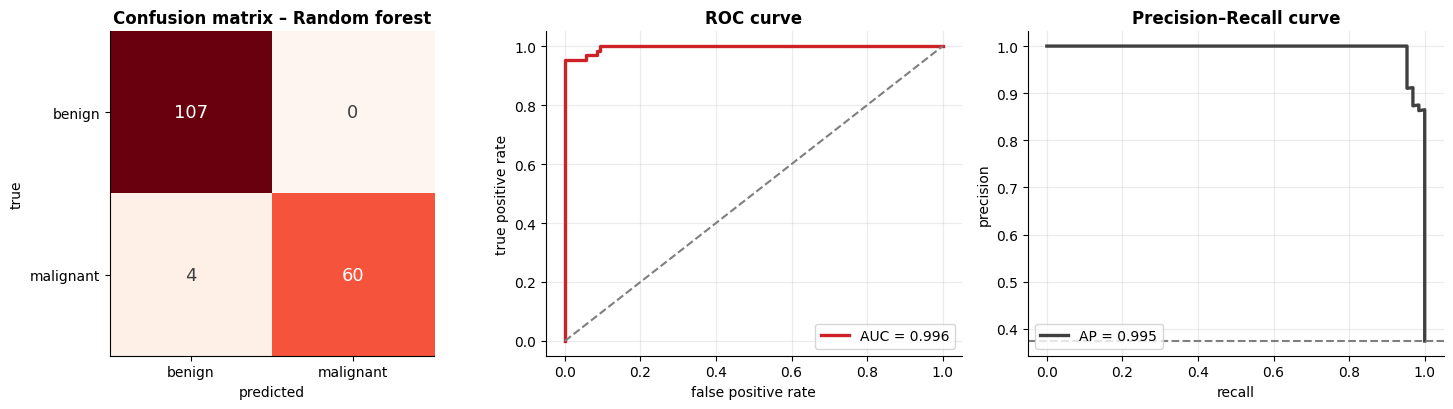

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Random forest,0.977,0.969,1.0,0.938,0.968,0.951,0.996,0.995


In [10]:
#Fit a Random Forest ( 300 Trees ) and Evaluate it
from sklearn.ensemble import RandomForestClassifier

t0 = time.perf_counter()
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=RANDOM_STATE, n_jobs=1).fit(X_train, y_train)
fit_time = time.perf_counter() - t0
p_rf = rf.predict_proba(X_test)[:, 1]
print(f"OOB accuracy: {rf.oob_score_:.3f} | test accuracy: {rf.score(X_test, y_test):.3f}")
results["Random forest"] = report_binary(y_test, rf.predict(X_test), p_rf, "Random forest", CLASSES)
extra["Random forest"] = {"log loss": log_loss(y_test, p_rf), "fit time (s)": fit_time, "size": "300 trees"}
results["Random forest"].to_frame().T

#### **Random-Forest-Specific Metrics**

* **OOB error** × number of trees (a validation that needs no extra data)
* **Feature importance:** impurity-based (**MDI**, biased towards continuous attributes) × **permutation** importance on the test set
* **Strength and correlation** of the trees: a good forest has **accurate** and **uncorrelated** trees

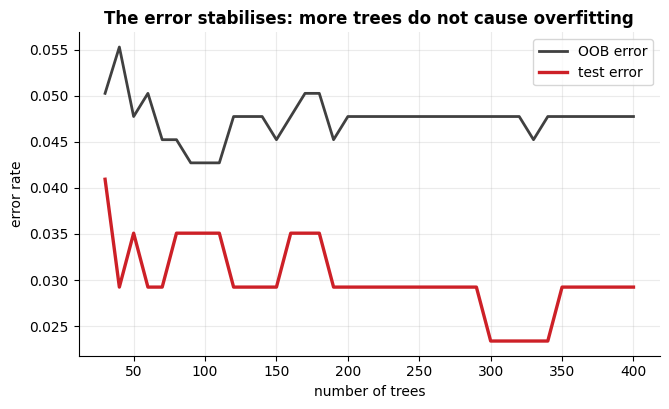

In [11]:
#OOB and Test Error as Trees Are Added ( warm_start )
rf_w = RandomForestClassifier(n_estimators=30, warm_start=True, oob_score=True, random_state=RANDOM_STATE)
ns_, oob_err, test_err = [], [], []
for n in range(30, 401, 10):
    rf_w.set_params(n_estimators=n).fit(X_train, y_train)
    ns_.append(n); oob_err.append(1 - rf_w.oob_score_); test_err.append(1 - rf_w.score(X_test, y_test))
plt.figure()
plt.plot(ns_, oob_err, color=DARK, lw=2, label="OOB error"); plt.plot(ns_, test_err, color=RED, lw=2.4, label="test error")
plt.xlabel("number of trees"); plt.ylabel("error rate"); plt.title("The error stabilises: more trees do not cause overfitting"); plt.legend()
plt.show()

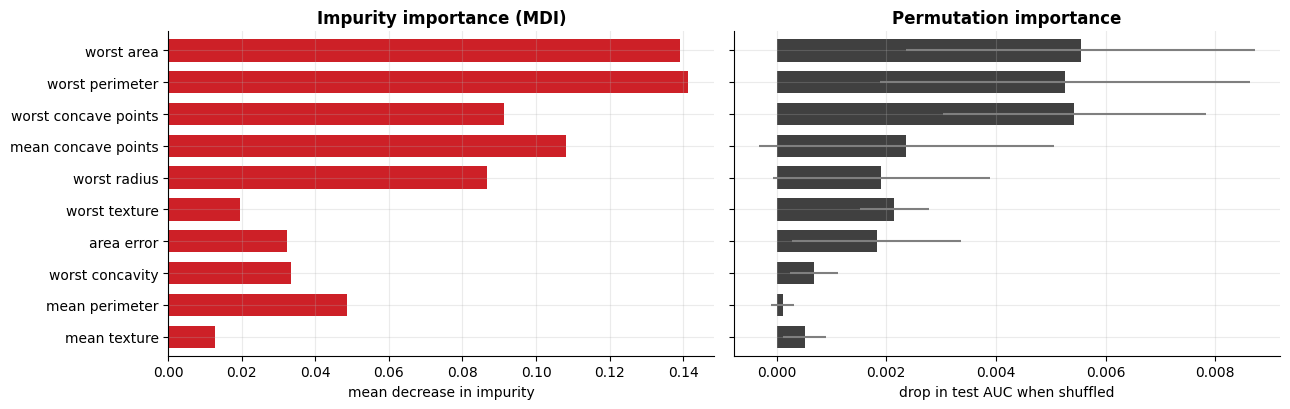

In [12]:
#Impurity (MDI) vs Permutation Importance
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="roc_auc")
mdi = pd.Series(rf.feature_importances_, index=X.columns)
pi = pd.Series(perm.importances_mean, index=X.columns)
top = (mdi.rank() + pi.rank()).sort_values().tail(10).index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
mdi[top].plot.barh(ax=axes[0], color=RED, width=0.7); axes[0].set_xlabel("mean decrease in impurity"); axes[0].set_title("Impurity importance (MDI)")
axes[1].barh(range(len(top)), pi[top], xerr=perm.importances_std[[list(X.columns).index(c) for c in top]], color=DARK, height=0.7, ecolor=GRAY); axes[1].set_xlabel("drop in test AUC when shuffled"); axes[1].set_title("Permutation importance")
plt.tight_layout(); plt.show()

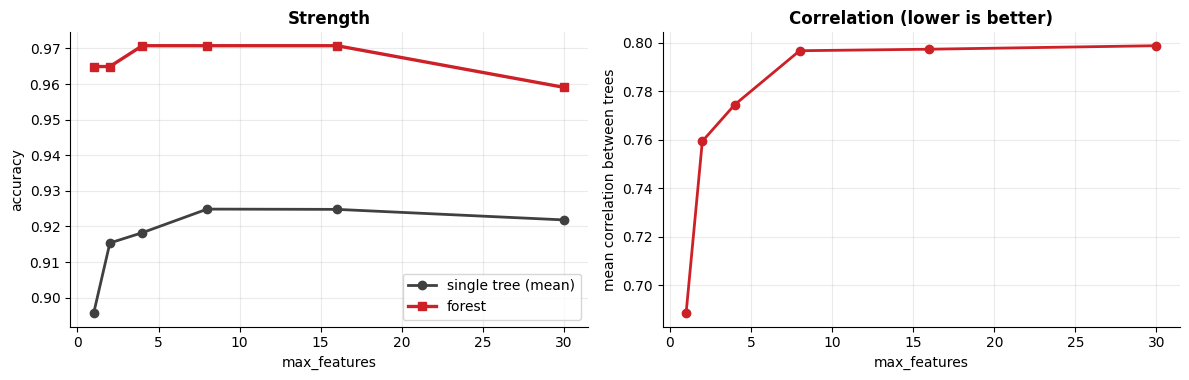

,max_features,mean tree accuracy,mean tree correlation,forest test accuracy,OOB accuracy
0,1,0.896,0.689,0.965,0.960
1,2,0.915,0.759,0.965,0.957
2,4,0.918,0.774,0.971,0.957
3,8,0.925,0.797,0.971,0.952
4,16,0.925,0.797,0.971,0.950
5,30,0.922,0.799,0.959,0.950


In [13]:
#Strength and Correlation of the Trees as a Function of max_features
rows = []
for mf in [1, 2, 4, 8, 16, 30]:
    m = RandomForestClassifier(n_estimators=150, max_features=mf, oob_score=True, random_state=RANDOM_STATE).fit(X_train, y_train)
    probs = np.array([t.predict_proba(X_test.to_numpy())[:, 1] for t in m.estimators_])
    corr = np.corrcoef(probs); mean_corr = corr[np.triu_indices_from(corr, k=1)].mean()
    tree_acc = np.mean([((p > 0.5).astype(int) == y_test.to_numpy()).mean() for p in probs])
    rows.append({"max_features": mf, "mean tree accuracy": tree_acc, "mean tree correlation": mean_corr, "forest test accuracy": m.score(X_test, y_test), "OOB accuracy": m.oob_score_})
sm = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].plot(sm["max_features"], sm["mean tree accuracy"], marker="o", color=DARK, lw=2, label="single tree (mean)"); axes[0].plot(sm["max_features"], sm["forest test accuracy"], marker="s", color=RED, lw=2.4, label="forest")
axes[0].set_xlabel("max_features"); axes[0].set_ylabel("accuracy"); axes[0].set_title("Strength"); axes[0].legend()
axes[1].plot(sm["max_features"], sm["mean tree correlation"], marker="o", color=RED, lw=2); axes[1].set_xlabel("max_features"); axes[1].set_ylabel("mean correlation between trees"); axes[1].set_title("Correlation (lower is better)")
plt.tight_layout(); plt.show()
sm.round(3)

### **4. Boosting**

Trees are trained **in sequence**; each new tree focuses on what the previous ones **got wrong**:

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

* **AdaBoost:** re-weights the **cases** (hard cases get more weight); each tree gets a weight $\alpha_m$ according to its error
* **Gradient Boosting:** each tree $h_m$ fits the **negative gradient** of the loss (the *pseudo-residuals*)
* The **learning rate** $\eta$ trades off the number of trees: a large $\eta$ reaches its best test loss with **few trees** and then overfits; a small $\eta$ needs **many more trees**

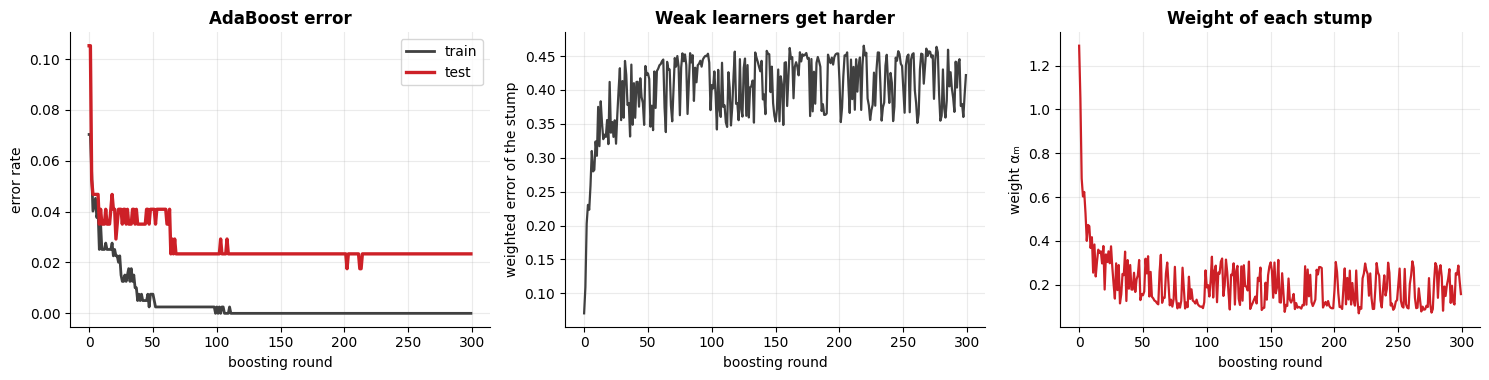

In [14]:
#AdaBoost with Decision Stumps ( Staged Error, Tree Errors and Tree Weights ) – NumPy Arrays Avoid a Feature-Name Warning in the staged_* Methods
from sklearn.ensemble import AdaBoostClassifier

Xtr_np, Xte_np = X_train.to_numpy(), X_test.to_numpy()
t0 = time.perf_counter(); ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=300, learning_rate=0.5, random_state=RANDOM_STATE).fit(Xtr_np, y_train); fit_time = time.perf_counter() - t0
stage_tr = [1 - accuracy_score(y_train, p) for p in ada.staged_predict(Xtr_np)]
stage_te = [1 - accuracy_score(y_test, p) for p in ada.staged_predict(Xte_np)]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
axes[0].plot(stage_tr, color=DARK, lw=2, label="train"); axes[0].plot(stage_te, color=RED, lw=2.4, label="test"); axes[0].set_xlabel("boosting round"); axes[0].set_ylabel("error rate"); axes[0].set_title("AdaBoost error"); axes[0].legend()
axes[1].plot(ada.estimator_errors_, color=DARK, lw=1.6); axes[1].set_xlabel("boosting round"); axes[1].set_ylabel("weighted error of the stump"); axes[1].set_title("Weak learners get harder")
axes[2].plot(ada.estimator_weights_, color=RED, lw=1.6); axes[2].set_xlabel("boosting round"); axes[2].set_ylabel("weight αₘ"); axes[2].set_title("Weight of each stump")
plt.tight_layout(); plt.show()
p_ada = ada.predict_proba(Xte_np)[:, 1]
results["AdaBoost"] = report_binary(y_test, ada.predict(Xte_np), p_ada, "AdaBoost", CLASSES, plot=False)
extra["AdaBoost"] = {"log loss": log_loss(y_test, p_ada), "fit time (s)": fit_time, "size": "300 stumps"}

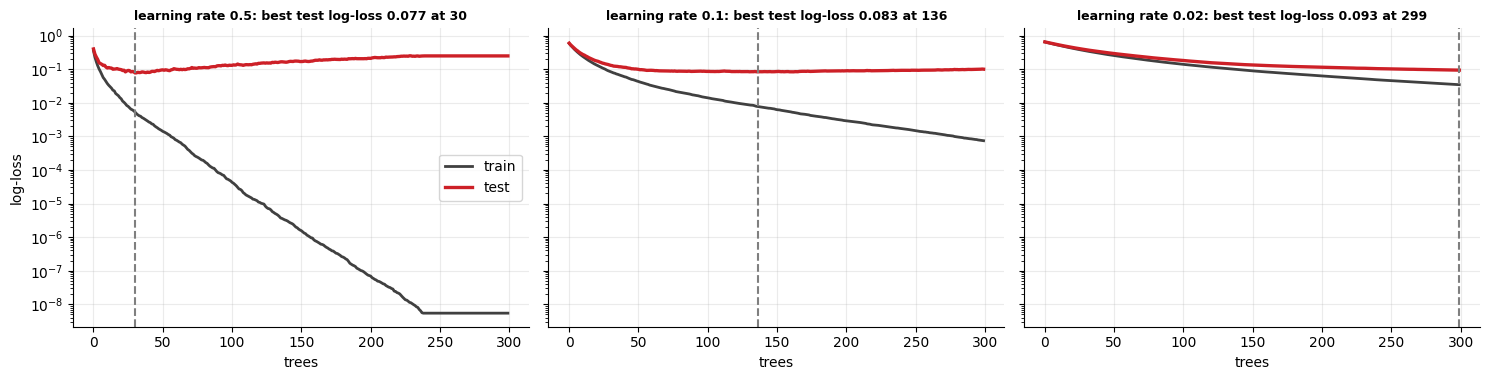

In [15]:
#Gradient Boosting: Learning Rate × Number of Trees ( Staged Log-Loss on Train and Test )
from sklearn.ensemble import GradientBoostingClassifier

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
gb_models = {}
for ax, lr in zip(axes, [0.5, 0.1, 0.02]):
    gb = GradientBoostingClassifier(n_estimators=300, learning_rate=lr, max_depth=2, random_state=RANDOM_STATE).fit(X_train, y_train)
    gb_models[lr] = gb
    tr = [log_loss(y_train, p[:, 1]) for p in gb.staged_predict_proba(X_train)]; te = [log_loss(y_test, p[:, 1]) for p in gb.staged_predict_proba(X_test)]
    ax.plot(tr, color=DARK, lw=2, label="train"); ax.plot(te, color=RED, lw=2.4, label="test"); ax.axvline(int(np.argmin(te)), color=GRAY, ls="--")
    ax.set_title(f"learning rate {lr}: best test log-loss {min(te):.3f} at {int(np.argmin(te))}", fontsize=9); ax.set_xlabel("trees"); ax.set_yscale("log")
axes[0].set_ylabel("log-loss"); axes[0].legend()
plt.tight_layout(); plt.show()

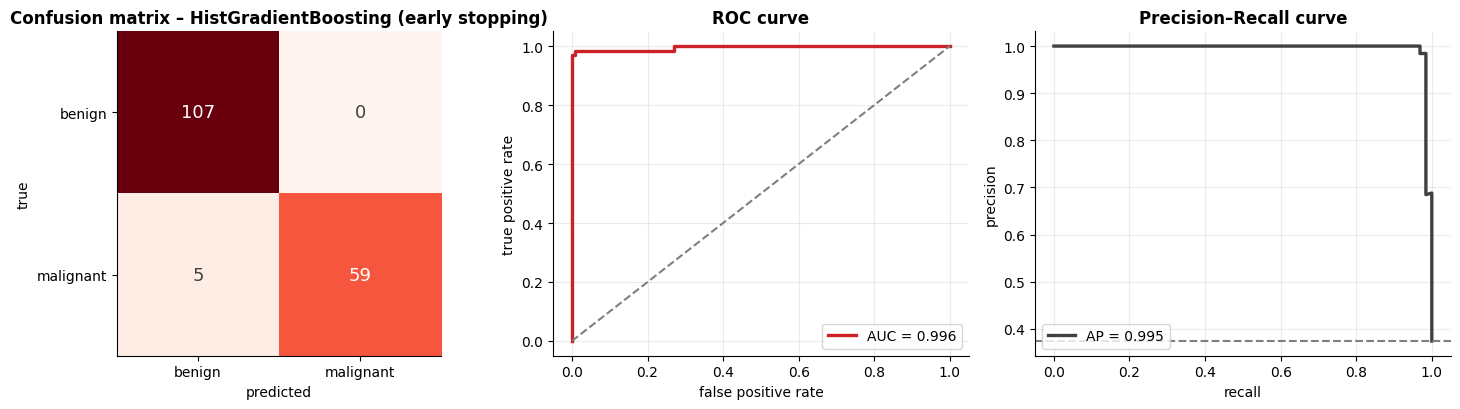

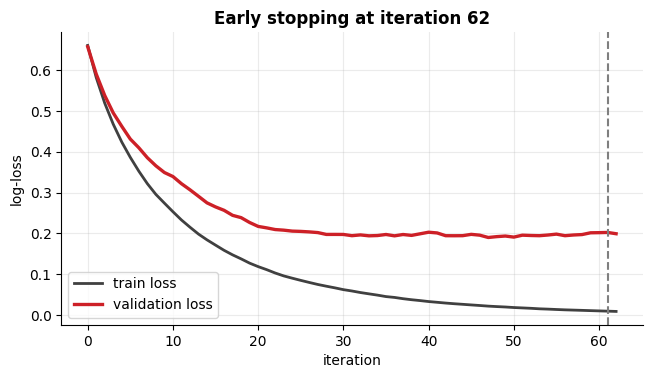

In [16]:
#Gradient Boosting and HistGradientBoosting ( Early Stopping on a Validation Split ): Evaluation and Learning Curves
from sklearn.ensemble import HistGradientBoostingClassifier

t0 = time.perf_counter(); gb = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=2, subsample=0.8, random_state=RANDOM_STATE).fit(X_train, y_train); fit_time = time.perf_counter() - t0
p_gb = gb.predict_proba(X_test)[:, 1]
results["Gradient boosting"] = report_binary(y_test, gb.predict(X_test), p_gb, "Gradient boosting", CLASSES, plot=False)
extra["Gradient boosting"] = {"log loss": log_loss(y_test, p_gb), "fit time (s)": fit_time, "size": "150 trees (depth 2)"}

t0 = time.perf_counter(); hgb = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.15, n_iter_no_change=15, random_state=RANDOM_STATE).fit(X_train, y_train); fit_time = time.perf_counter() - t0
p_hgb = hgb.predict_proba(X_test)[:, 1]
results["HistGradientBoosting"] = report_binary(y_test, hgb.predict(X_test), p_hgb, "HistGradientBoosting (early stopping)", CLASSES)
extra["HistGradientBoosting"] = {"log loss": log_loss(y_test, p_hgb), "fit time (s)": fit_time, "size": f"{hgb.n_iter_} iterations"}

plt.figure(figsize=(7.5, 3.8))
plt.plot(-hgb.train_score_, color=DARK, lw=2, label="train loss"); plt.plot(-hgb.validation_score_, color=RED, lw=2.4, label="validation loss")
plt.axvline(hgb.n_iter_ - 1, color=GRAY, ls="--"); plt.xlabel("iteration"); plt.ylabel("log-loss"); plt.title(f"Early stopping at iteration {hgb.n_iter_}"); plt.legend()
plt.show()

### **5. XGBoost (from Scratch)**

XGBoost minimises a **regularised** objective with a **second-order** Taylor expansion of the loss. With gradients $g_i$ and hessians $h_i$ of a leaf's cases:

$$w^* = -\frac{G}{H + \lambda} \qquad \text{gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{G^2}{H + \lambda}\right] - \gamma$$

* $\lambda$: **L2 penalty** on leaf weights · $\gamma$: **minimum gain** to split (pruning) · $\eta$: learning rate
* For the logistic loss: $g = p - y$ and $h = p(1-p)$

We implement the algorithm (exact greedy splits) and **verify** the tree builder against `DecisionTreeRegressor`.

In [17]:
#XGBoost-Style Gradient Boosting from Scratch ( Gradient + Hessian, Regularised Leaf Weights, Gain with γ, Subsampling )
from sklearn.base import BaseEstimator, ClassifierMixin
from scipy.special import expit

class XGBoostScratch(ClassifierMixin, BaseEstimator):
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3, reg_lambda=1.0, gamma=0.0, min_child_weight=1.0,
                 subsample=1.0, colsample_bytree=1.0, objective="logistic", random_state=0):
        self.n_estimators, self.learning_rate, self.max_depth, self.reg_lambda, self.gamma = n_estimators, learning_rate, max_depth, reg_lambda, gamma
        self.min_child_weight, self.subsample, self.colsample_bytree, self.objective, self.random_state = min_child_weight, subsample, colsample_bytree, objective, random_state

    def _grad_hess(self, y, F):
        if self.objective == "logistic":
            p = expit(F)
            return p - y, np.maximum(p * (1 - p), 1e-16)
        return F - y, np.ones_like(y)                                                                     # squared error

    def _build(self, X, g, h, idx, depth, feats):
        G, H = g[idx].sum(), h[idx].sum()
        leaf = {"w": -G / (H + self.reg_lambda)}
        if depth >= self.max_depth or len(idx) < 2:
            return leaf
        best_gain, best = 0.0, None
        for f in feats:
            order = np.argsort(X[idx, f], kind="stable")
            xs, gs, hs = X[idx, f][order], g[idx][order], h[idx][order]
            GL, HL = np.cumsum(gs)[:-1], np.cumsum(hs)[:-1]
            GR, HR = G - GL, H - HL
            gain = 0.5 * (GL ** 2 / (HL + self.reg_lambda) + GR ** 2 / (HR + self.reg_lambda) - G ** 2 / (H + self.reg_lambda)) - self.gamma
            gain = np.where((xs[1:] > xs[:-1]) & (HL >= self.min_child_weight) & (HR >= self.min_child_weight), gain, -np.inf)
            k = int(np.argmax(gain))
            if gain[k] > best_gain:
                best_gain, best = gain[k], (f, (xs[k] + xs[k + 1]) / 2)
        if best is None:
            return leaf
        f, thr = best
        self.gain_[f] += best_gain; self.cover_[f] += H; self.weight_[f] += 1
        left = idx[X[idx, f] <= thr]; right = idx[X[idx, f] > thr]
        return {"f": f, "thr": thr, "left": self._build(X, g, h, left, depth + 1, feats), "right": self._build(X, g, h, right, depth + 1, feats)}

    def _tree_predict(self, node, X):
        if "w" in node:
            return np.full(len(X), node["w"])
        out, m = np.empty(len(X)), X[:, node["f"]] <= node["thr"]
        out[m] = self._tree_predict(node["left"], X[m]); out[~m] = self._tree_predict(node["right"], X[~m])
        return out

    def fit(self, X, y, eval_set=None):
        X, y = np.asarray(X, float), np.asarray(y, float)
        rng = np.random.default_rng(self.random_state)
        self.classes_ = np.array([0, 1])
        self.gain_, self.cover_, self.weight_ = np.zeros(X.shape[1]), np.zeros(X.shape[1]), np.zeros(X.shape[1])
        p0 = y.mean()
        self.f0_ = np.log(p0 / (1 - p0)) if self.objective == "logistic" else p0
        F, self.trees_, self.history_ = np.full(len(y), self.f0_), [], {"train": [], "eval": []}
        F_eval = np.full(len(eval_set[1]), self.f0_) if eval_set is not None else None
        for _ in range(self.n_estimators):
            g, h = self._grad_hess(y, F)
            rows = np.sort(rng.choice(len(y), int(self.subsample * len(y)), replace=False)) if self.subsample < 1 else np.arange(len(y))
            feats = np.sort(rng.choice(X.shape[1], max(1, int(self.colsample_bytree * X.shape[1])), replace=False)) if self.colsample_bytree < 1 else range(X.shape[1])
            tree = self._build(X, g, h, rows, 0, feats)
            self.trees_.append(tree)
            F += self.learning_rate * self._tree_predict(tree, X)
            self.history_["train"].append(log_loss(y, expit(F), labels=[0, 1]) if self.objective == "logistic" else np.mean((y - F) ** 2))
            if eval_set is not None:
                F_eval += self.learning_rate * self._tree_predict(tree, np.asarray(eval_set[0], float))
                self.history_["eval"].append(log_loss(eval_set[1], expit(F_eval), labels=[0, 1]) if self.objective == "logistic" else np.mean((eval_set[1] - F_eval) ** 2))
        return self

    def predict_raw(self, X):
        X = np.asarray(X, float)
        return self.f0_ + self.learning_rate * sum(self._tree_predict(t, X) for t in self.trees_)

    def predict_proba(self, X):
        p = expit(self.predict_raw(X))
        return np.c_[1 - p, p]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

In [18]:
#Verify the Tree Builder: One Tree with Squared Error, No Regularisation == scikit-learn DecisionTreeRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.datasets import load_diabetes

Xr, yr = load_diabetes(return_X_y=True)
mine = XGBoostScratch(n_estimators=1, learning_rate=1.0, max_depth=3, reg_lambda=0.0, gamma=0.0, min_child_weight=1e-12, objective="squared").fit(Xr, yr)
ref = DecisionTreeRegressor(max_depth=3, random_state=0).fit(Xr, yr)
print("predictions identical to DecisionTreeRegressor(max_depth=3):", np.allclose(mine.predict_raw(Xr), ref.predict(Xr)))

predictions identical to DecisionTreeRegressor(max_depth=3): True


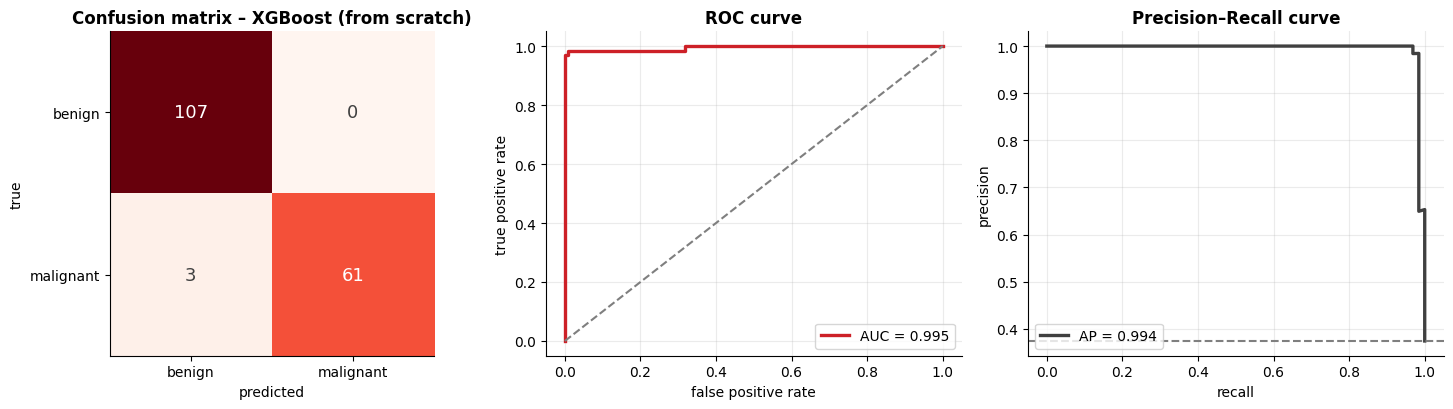

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
XGBoost (from scratch),0.982,0.977,1.0,0.953,0.976,0.963,0.995,0.994


In [19]:
#Fit the XGBoost-Style Model on the Breast Cancer Data and Evaluate it
t0 = time.perf_counter()
xgb_s = XGBoostScratch(n_estimators=150, learning_rate=0.1, max_depth=3, reg_lambda=1.0, gamma=0.0, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE).fit(X_train, y_train, eval_set=(X_test, y_test))
fit_time = time.perf_counter() - t0
p_xgb = xgb_s.predict_proba(X_test)[:, 1]
results["XGBoost (scratch)"] = report_binary(y_test, xgb_s.predict(X_test), p_xgb, "XGBoost (from scratch)", CLASSES)
extra["XGBoost (scratch)"] = {"log loss": log_loss(y_test, p_xgb), "fit time (s)": fit_time, "size": "150 trees (depth 3)"}
results["XGBoost (scratch)"].to_frame().T

#### **XGBoost-Specific Metrics**

* **Learning curve** (train × validation log-loss)
* **Effect of the regularisation** $\lambda$ and $\gamma$ (and tree depth) on the validation loss
* **Importance by gain, cover and weight** – three views of the same trees

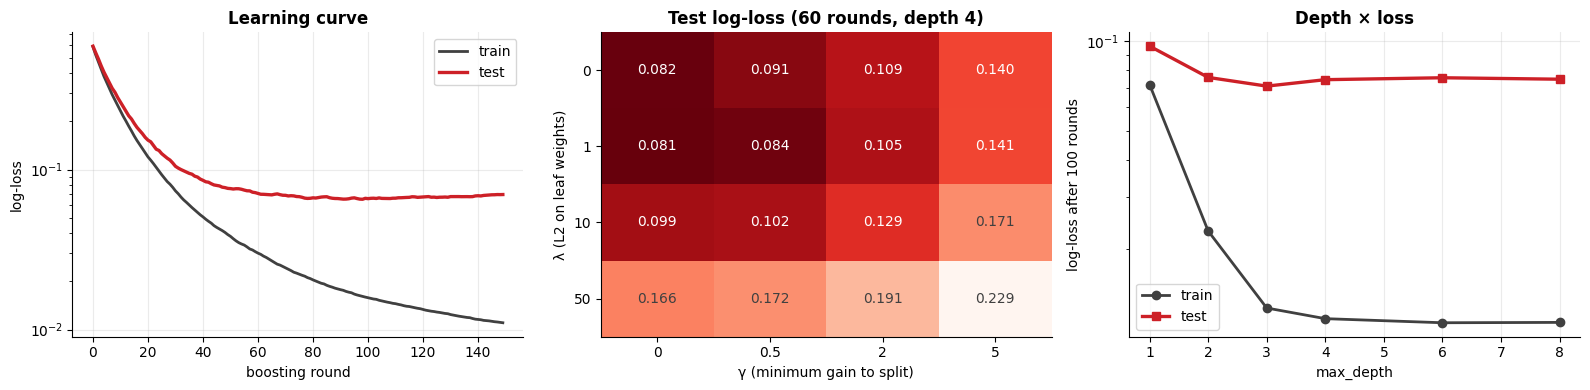

In [20]:
#Learning Curve and the Effect of λ, γ and Depth on the Test Log-Loss
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(xgb_s.history_["train"], color=DARK, lw=2, label="train"); axes[0].plot(xgb_s.history_["eval"], color=RED, lw=2.4, label="test")
axes[0].set_xlabel("boosting round"); axes[0].set_ylabel("log-loss"); axes[0].set_yscale("log"); axes[0].set_title("Learning curve"); axes[0].legend()

lambdas, gammas = [0, 1, 10, 50], [0, 0.5, 2, 5]
grid = np.zeros((4, 4))
for i, lam in enumerate(lambdas):
    for j, gam in enumerate(gammas):
        m = XGBoostScratch(n_estimators=60, learning_rate=0.1, max_depth=4, reg_lambda=lam, gamma=gam, random_state=RANDOM_STATE).fit(X_train, y_train)
        grid[i, j] = log_loss(y_test, m.predict_proba(X_test)[:, 1])
axes[1].imshow(grid, cmap="Reds_r", aspect="auto"); axes[1].grid(False); axes[1].set_xticks(range(4)); axes[1].set_xticklabels(gammas); axes[1].set_yticks(range(4)); axes[1].set_yticklabels(lambdas)
axes[1].set_xlabel("γ (minimum gain to split)"); axes[1].set_ylabel("λ (L2 on leaf weights)"); axes[1].set_title("Test log-loss (60 rounds, depth 4)"); annotate_heatmap(axes[1], -grid, "{:.3f}")
for row in axes[1].texts:
    row.set_text(row.get_text().replace("-", ""))

depth_loss = []
for d in [1, 2, 3, 4, 6, 8]:
    m = XGBoostScratch(n_estimators=100, learning_rate=0.1, max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train, eval_set=(X_test, y_test))
    depth_loss.append((d, m.history_["train"][-1], m.history_["eval"][-1]))
dl = pd.DataFrame(depth_loss, columns=["depth", "train", "test"])
axes[2].plot(dl["depth"], dl["train"], marker="o", color=DARK, lw=2, label="train"); axes[2].plot(dl["depth"], dl["test"], marker="s", color=RED, lw=2.4, label="test")
axes[2].set_xlabel("max_depth"); axes[2].set_ylabel("log-loss after 100 rounds"); axes[2].set_yscale("log"); axes[2].set_title("Depth × loss"); axes[2].legend()
plt.tight_layout(); plt.show()

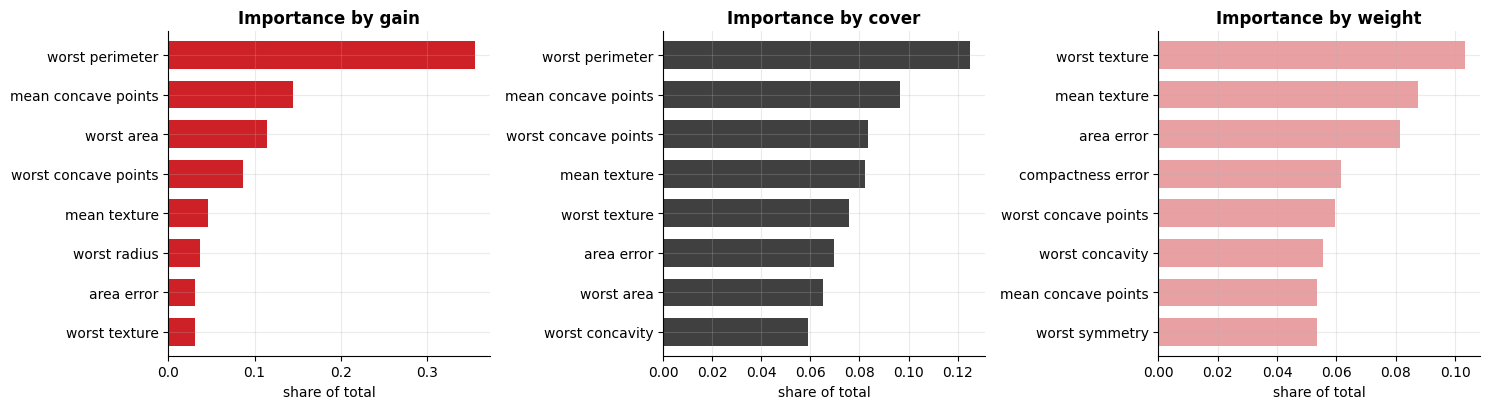

In [21]:
#Feature Importance by Gain, Cover and Weight ( Number of Splits )
imps = pd.DataFrame({"gain": xgb_s.gain_, "cover": xgb_s.cover_, "weight": xgb_s.weight_}, index=X.columns)
imps = imps / imps.sum()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, color in zip(axes, ["gain", "cover", "weight"], [RED, DARK, SOFT]):
    imps[col].sort_values().tail(8).plot.barh(ax=ax, color=color, width=0.7); ax.set_title(f"Importance by {col}"); ax.set_xlabel("share of total")
plt.tight_layout(); plt.show()

In [22]:
#Optional: the Same Model with the Real XGBoost Library ( Runs only if xgboost is Installed, e.g. in Google Colab )
try:
    from xgboost import XGBClassifier
    xgb_lib = XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=3, reg_lambda=1.0, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE).fit(X_train, y_train)
    p_lib = xgb_lib.predict_proba(X_test)[:, 1]
    print(f"XGBoost library -> accuracy {accuracy_score(y_test, xgb_lib.predict(X_test)):.3f} | ROC AUC {roc_auc_score(y_test, p_lib):.3f} | log-loss {log_loss(y_test, p_lib):.3f}")
    print(f"our implementation -> accuracy {accuracy_score(y_test, xgb_s.predict(X_test)):.3f} | ROC AUC {roc_auc_score(y_test, p_xgb):.3f} | log-loss {log_loss(y_test, p_xgb):.3f}")
except ImportError:
    print("xgboost is not installed in this environment (it is in Google Colab: `pip install xgboost`). The from-scratch model above implements the same algorithm.")

xgboost is not installed in this environment (it is in Google Colab: `pip install xgboost`). The from-scratch model above implements the same algorithm.


### **6. Comparing the Tree-Based Classifiers**

,accuracy,precision,recall,F1,ROC AUC,PR AUC,log loss,fit time (s),size
Decision tree (pruned),0.895,0.926,0.781,0.847,0.870,0.838,0.557,0.007,15 leaves
Random forest,0.977,1.000,0.938,0.968,0.996,0.995,0.104,0.532,300 trees
AdaBoost,0.977,1.000,0.938,0.968,0.996,0.995,0.427,0.822,300 stumps
Gradient boosting,0.965,1.000,0.906,0.951,0.997,0.996,0.084,0.299,150 trees (depth 2)
HistGradientBoosting,0.971,1.000,0.922,0.959,0.996,0.995,0.081,0.121,62 iterations
XGBoost (scratch),0.982,1.000,0.953,0.976,0.995,0.994,0.07,1.279,150 trees (depth 3)


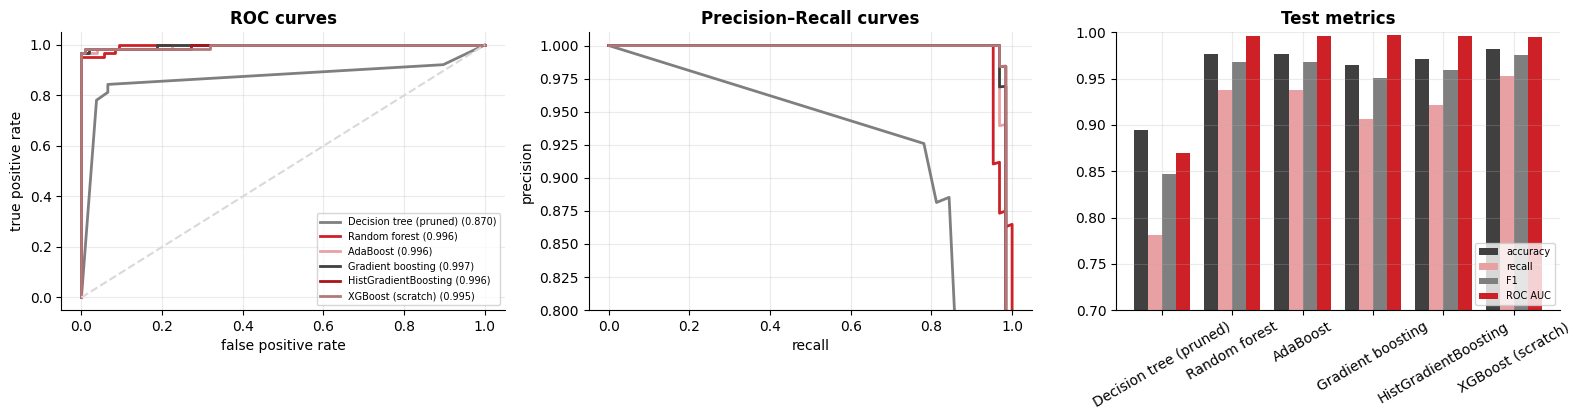

In [23]:
#Comparison Table and ROC / Precision-Recall Curves on the Test Set
scores = {"Decision tree (pruned)": p_tree, "Random forest": p_rf, "AdaBoost": p_ada, "Gradient boosting": p_gb, "HistGradientBoosting": p_hgb, "XGBoost (scratch)": p_xgb}
comparison = pd.DataFrame(results).T[["accuracy", "precision", "recall", "F1", "ROC AUC", "PR AUC"]]
comparison = comparison.join(pd.DataFrame(extra).T)
display(comparison.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
cols = [GRAY, RED, SOFT, DARK, "#A8141A", "#B07A7C"]
for (name, s), color in zip(scores.items(), cols):
    f, t, _ = roc_curve(y_test, s); axes[0].plot(f, t, color=color, lw=2, label=f"{name} ({roc_auc_score(y_test, s):.3f})")
    p, r, _ = precision_recall_curve(y_test, s); axes[1].plot(r, p, color=color, lw=2)
axes[0].plot([0, 1], [0, 1], color=LIGHT, ls="--"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate"); axes[0].set_title("ROC curves"); axes[0].legend(fontsize=7, loc="lower right")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision–Recall curves"); axes[1].set_ylim(0.8, 1.01)
comparison[["accuracy", "recall", "F1", "ROC AUC"]].plot.bar(ax=axes[2], color=[DARK, SOFT, GRAY, RED], width=0.8, rot=30); axes[2].set_ylim(0.7, 1.0); axes[2].set_title("Test metrics"); axes[2].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

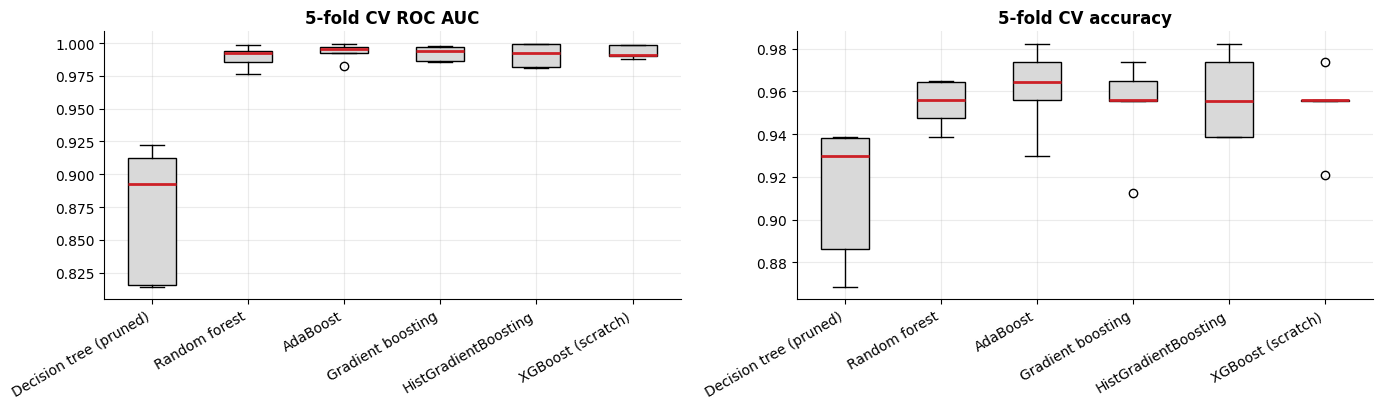

,mean AUC,std
Decision tree (pruned),0.871,0.047
Random forest,0.990,0.008
AdaBoost,0.993,0.006
Gradient boosting,0.992,0.005
HistGradientBoosting,0.991,0.008
XGBoost (scratch),0.993,0.004


In [24]:
#Stability: 5-Fold Cross-Validated ROC AUC and Accuracy of Each Model ( Whole Dataset )
models = {"Decision tree (pruned)": DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=RANDOM_STATE),
          "Random forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
          "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE),
          "Gradient boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=2, random_state=RANDOM_STATE),
          "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
          "XGBoost (scratch)": XGBoostScratch(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE)}
cv_auc = {n: cross_val_score(m, X, y, cv=cv5, scoring="roc_auc") for n, m in models.items()}
cv_acc = {n: cross_val_score(m, X, y, cv=cv5, scoring="accuracy") for n, m in models.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, data, title in zip(axes, [cv_auc, cv_acc], ["ROC AUC", "accuracy"]):
    bp = ax.boxplot(list(data.values()), patch_artist=True, medianprops=dict(color=RED, lw=2))
    for b in bp["boxes"]:
        b.set_facecolor(LIGHT)
    ax.set_xticks(range(1, len(data) + 1)); ax.set_xticklabels(list(data.keys()), rotation=30, ha="right"); ax.set_title(f"5-fold CV {title}")
plt.tight_layout(); plt.show()
pd.DataFrame({n: [v.mean(), v.std()] for n, v in cv_auc.items()}, index=["mean AUC", "std"]).T.round(4)

### **7. Multi-Class Example: Handwritten Digits (10 Classes)**

The same models handle **more than two classes**: the **confusion matrix** is 10×10 and the ROC is **one-vs-rest** (one curve per class).

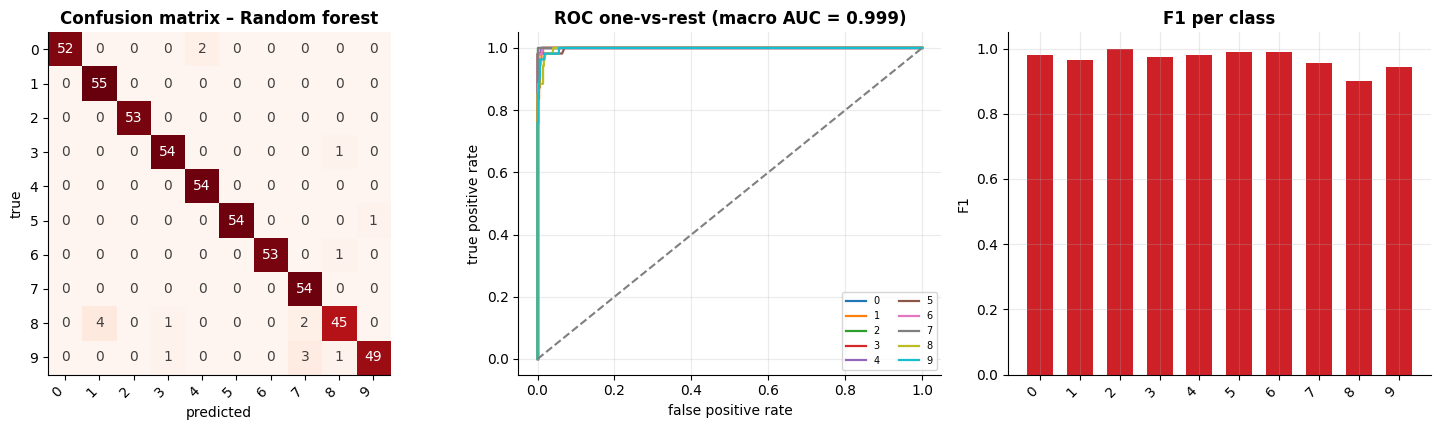

,accuracy,balanced acc.,macro precision,macro recall,macro F1,MCC,ROC AUC (ovr),log loss
Decision tree,0.830,0.829,0.832,0.829,0.829,0.811,0.928,4.186
Random forest,0.969,0.968,0.969,0.968,0.968,0.965,0.999,0.327
HistGradientBoosting,0.959,0.959,0.960,0.959,0.959,0.955,0.998,0.183


In [25]:
#Digits Dataset: Decision Tree, Random Forest and HistGradientBoosting ( Multi-Class Metrics )
from sklearn.datasets import load_digits

Xg, yg = load_digits(return_X_y=True)
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=0.3, random_state=RANDOM_STATE, stratify=yg)
digit_names = [str(d) for d in range(10)]

digit_models = {"Decision tree": DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE), "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
                "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_STATE)}
digit_res = {}
for name, m in digit_models.items():
    m.fit(Xg_tr, yg_tr)
    digit_res[name] = report_multiclass(yg_te, m.predict(Xg_te), m.predict_proba(Xg_te), digit_names, name, plot=(name == "Random forest"))
pd.DataFrame(digit_res).T.round(3)

### **8. Summary**

| | **Decision tree** | **Random forest** | **AdaBoost / Gradient boosting** | **XGBoost** |
|---|---|---|---|---|
| Interpretability | ✅ rules | partial (importances) | partial | partial |
| Main weakness | high variance | large model, slow prediction | sensitive to noise, sequential | many hyperparameters |
| Specific metrics | depth, leaves, pruning path | OOB error, permutation importance, tree correlation | staged error, tree weights, early stopping | gain/cover/weight, λ and γ effect |
| Python | `DecisionTreeClassifier` | `RandomForestClassifier` | `AdaBoostClassifier`, `GradientBoostingClassifier`, `HistGradientBoostingClassifier` | `xgboost.XGBClassifier` |

* **Trees need no scaling**, handle non-linear interactions and are robust to outliers
* **Bagging** attacks the **variance**, **boosting** attacks the **bias**; both beat a single tree
* On **tabular data**, boosted trees are usually the strongest baseline – always compare with **cross-validation**